In [27]:
import random
import copy
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt


def set_global_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

import logging

# Configure logging to overwrite "_.log" every run (mode="w")
logging.basicConfig(
    level=logging.INFO,
    format="%(message)s",
    handlers=[
        logging.FileHandler("q3_b.log", mode="w"),  # "w" overwrites, "a" appends
        logging.StreamHandler()
    ],
    force=True  # Resets any existing logging handlers
)
logger = logging.getLogger(__name__)

In [28]:
class PairedCorruptedDataset(Dataset):
    def __init__(self, images_uint8, labels, mean, std, noise_std=0.25, noise_seed=260007):
        self.labels = labels
        mean_t = torch.tensor(mean, dtype=torch.float32).view(1, 3, 1, 1)
        std_t = torch.tensor(std, dtype=torch.float32).view(1, 3, 1, 1)

        clean_01 = torch.from_numpy(images_uint8).permute(0, 3, 1, 2).float() / 255.0

        gen = torch.Generator()
        gen.manual_seed(noise_seed)
        noise = torch.randn(clean_01.shape, generator=gen) * noise_std
        corrupt_01 = torch.clamp(clean_01 + noise, 0.0, 1.0)

        self.clean_norm = (clean_01 - mean_t) / std_t
        self.corrupt_norm = (corrupt_01 - mean_t) / std_t

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.corrupt_norm[idx], self.clean_norm[idx], int(self.labels[idx])


def get_denoising_loaders(seed=260007, noise_std=0.25, data_dir="./data", batch_size=1024):
    raw_train = datasets.CIFAR10(root=data_dir, train=True, download=True)
    raw_test = datasets.CIFAR10(root=data_dir, train=False, download=True)

    all_images = raw_train.data
    all_labels = np.array(raw_train.targets)

    indices = np.arange(len(all_labels))
    train_idx, val_idx = train_test_split(
        indices, test_size=5000, random_state=seed, stratify=all_labels
    )

    X_train, y_train = all_images[train_idx], all_labels[train_idx]
    X_val, y_val = all_images[val_idx], all_labels[val_idx]
    X_test, y_test = raw_test.data, np.array(raw_test.targets)

    train_float = X_train.astype(np.float32) / 255.0
    mean = train_float.mean(axis=(0, 1, 2)).tolist()
    std = train_float.std(axis=(0, 1, 2)).tolist()

    train_ds = PairedCorruptedDataset(X_train, y_train, mean, std, noise_std=noise_std, noise_seed=seed)
    val_ds = PairedCorruptedDataset(X_val, y_val, mean, std, noise_std=noise_std, noise_seed=seed + 1)
    test_ds = PairedCorruptedDataset(X_test, y_test, mean, std, noise_std=noise_std, noise_seed=seed + 2)

    g = torch.Generator()
    g.manual_seed(seed)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=2, generator=g)
    val_loader = DataLoader(val_ds, batch_size=256, shuffle=False, num_workers=2)
    test_loader = DataLoader(test_ds, batch_size=256, shuffle=False, num_workers=2)

    return train_loader, val_loader, test_loader, mean, std

In [29]:
class ConvAutoencoder(nn.Module):
    def __init__(self, bottleneck_dim: int = 512):
        super().__init__()
        self.bottleneck_dim = bottleneck_dim

        self.encoder_conv = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
        )
        self.encoder_fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, bottleneck_dim),
            nn.ReLU(inplace=True)
        )

        self.decoder_fc = nn.Sequential(
            nn.Linear(bottleneck_dim, 128 * 4 * 4),
            nn.ReLU(inplace=True)
        )
        self.decoder_conv = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(32, 3, kernel_size=3, stride=2, padding=1, output_padding=1),
        )

    def encode(self, x):
        return self.encoder_fc(self.encoder_conv(x))

    def decode(self, z):
        return self.decoder_conv(self.decoder_fc(z).view(-1, 128, 4, 4))

    def forward(self, x):
        return self.decode(self.encode(x))


class ConvNetMatched(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(2048, 150),
            nn.ReLU(),
            nn.Linear(150, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

In [30]:
def evaluate_denoising_mse(ae_model: nn.Module, loader: DataLoader, device: str) -> float:
    ae_model.eval()
    criterion = nn.MSELoss(reduction="sum")
    total_loss, total_elements = 0.0, 0

    with torch.no_grad():
        for x_corrupt, x_clean, _ in loader:
            x_corrupt, x_clean = x_corrupt.to(device), x_clean.to(device)
            recon = ae_model(x_corrupt)
            total_loss += criterion(recon, x_clean).item()
            total_elements += x_clean.numel()

    return total_loss / total_elements


def train_denoising_ae(model, train_loader, val_loader, epochs=30, lr=1e-3, weight_decay=1e-4, device="cpu"):
    model = model.to(device)
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    best_val_mse = float("inf")
    best_weights = copy.deepcopy(model.state_dict())

    for epoch in range(1, epochs + 1):
        model.train()
        for x_corrupt, x_clean, _ in train_loader:
            x_corrupt, x_clean = x_corrupt.to(device), x_clean.to(device)
            optimizer.zero_grad()
            recon = model(x_corrupt)
            loss = criterion(recon, x_clean)
            loss.backward()
            optimizer.step()

        val_mse = evaluate_denoising_mse(model, val_loader, device)
        if val_mse < best_val_mse:
            best_val_mse = val_mse
            best_weights = copy.deepcopy(model.state_dict())

        if epoch == 1 or epoch % 10 == 0 or epoch == epochs:
            logger.info(f"  [DAE d={model.bottleneck_dim}] Epoch {epoch:2d}/{epochs} | Val Clean-Target MSE: {val_mse:.6f}")

    model.load_state_dict(best_weights)
    return model, best_val_mse


def evaluate_downstream_classifier(classifier: nn.Module, loader: DataLoader, mode: str, ae_model=None, device="cpu") -> float:
    classifier.eval()
    if ae_model is not None:
        ae_model.eval()

    correct, total = 0, 0
    with torch.no_grad():
        for x_corrupt, x_clean, y in loader:
            y = y.to(device)
            if mode == "clean":
                inp = x_clean.to(device)
            elif mode == "corrupt":
                inp = x_corrupt.to(device)
            elif mode in ("clean_ae", "dae"):
                inp = ae_model(x_corrupt.to(device))
            else:
                raise ValueError(f"Unknown evaluation mode: {mode}")

            preds = classifier(inp).argmax(dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)

    return 100.0 * correct / total


def plot_denoising_comparison(clean_ae, dae, test_loader, mean, std, device="cpu", save_path="q3_part_b_denoising_grid.png"):
    x_corrupt, x_clean, _ = next(iter(test_loader))
    x_corrupt_s = x_corrupt[:6].to(device)
    x_clean_s = x_clean[:6].to(device)

    clean_ae.eval()
    dae.eval()
    with torch.no_grad():
        recon_clean_ae = clean_ae(x_corrupt_s)
        recon_dae = dae(x_corrupt_s)

    mean_t = torch.tensor(mean).view(1, 3, 1, 1).to(device)
    std_t = torch.tensor(std).view(1, 3, 1, 1).to(device)

    def unnorm(t):
        return torch.clamp(t * std_t + mean_t, 0.0, 1.0).cpu().permute(0, 2, 3, 1).numpy()

    rows = [
        ("Clean Target (Ground Truth)", unnorm(x_clean_s)),
        ("Corrupted Input (Gaussian σ=0.25)", unnorm(x_corrupt_s)),
        ("Clean AE Baseline Recon", unnorm(recon_clean_ae)),
        ("Denoising AE (DAE) Recon", unnorm(recon_dae)),
    ]

    fig, axes = plt.subplots(4, 6, figsize=(12, 8.2))
    for r_idx, (title, imgs) in enumerate(rows):
        for c_idx in range(6):
            axes[r_idx, c_idx].imshow(imgs[c_idx])
            axes[r_idx, c_idx].axis("off")
            if c_idx == 0:
                axes[r_idx, c_idx].set_title(title, loc="left", fontsize=10, fontweight="bold")

    plt.tight_layout()
    plt.savefig(save_path, dpi=300)
    plt.show()

Running Question 3 Part (b) on device: cuda

Training Denoising Autoencoder (d=512, Gaussian noise σ=0.25)...
  [DAE d=512] Epoch  1/30 | Val Clean-Target MSE: 0.474843
  [DAE d=512] Epoch 10/30 | Val Clean-Target MSE: 0.157705
  [DAE d=512] Epoch 20/30 | Val Clean-Target MSE: 0.125921
  [DAE d=512] Epoch 30/30 | Val Clean-Target MSE: 0.115680
  Saved Denoising AE weights to dae_d512.pt

QUESTION 3 PART (b) DELIVERABLES SUMMARY (OFFICIAL TEST SET)
Corruption: Additive Gaussian Noise (σ = 0.25 on [0,1] scale, clipped to [0,1])
Input to Fixed ConvNetMatched        | Test Clean-Target MSE |   Test Accuracy
----------------------------------------------------------------------------------
1. Clean Images (Reference)          |              0.000000 |          75.22%
2. Corrupted Images (Unfiltered)     |                   N/A |          18.29%
3. Clean AE Reconstructions (Q3a)    |              0.146122 |          31.94%
4. Denoising AE Reconstructions      |              0.114896 |       

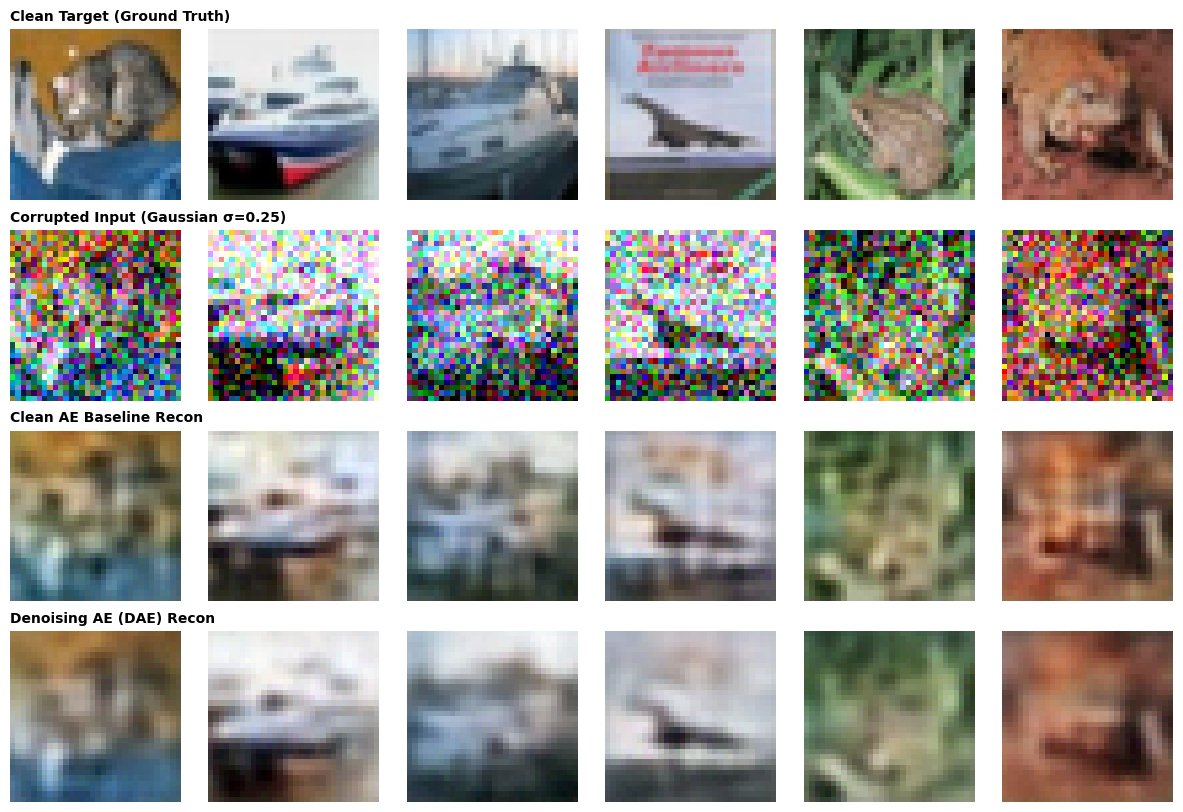

In [31]:
if __name__ == "__main__":
    SEED = 260007
    EPOCHS = 30
    LR = 1e-3
    WD = 1e-4
    NOISE_STD = 0.25
    BOTTLENECK_DIM = 512  # Matches selected model from Part (a)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    logger.info(f"Running Question 3 Part (b) on device: {DEVICE}")

    train_loader, val_loader, test_loader, mean, std = get_denoising_loaders(
        seed=SEED, noise_std=NOISE_STD
    )

    # 1. Load Fixed Clean CNN Classifier from Question 1(a)
    cnn_fixed = ConvNetMatched().to(DEVICE)
    cnn_fixed.load_state_dict(torch.load("cnn_matched.pt", map_location=DEVICE))
    for p in cnn_fixed.parameters():
        p.requires_grad = False

    # 2. Load Selected Clean Autoencoder Baseline from Question 3 Part (a)
    clean_ae = ConvAutoencoder(bottleneck_dim=BOTTLENECK_DIM).to(DEVICE)
    clean_ae.load_state_dict(torch.load("cae_selected_clean.pt", map_location=DEVICE))

    # 3. Train Denoising Autoencoder (DAE) Unsupervised (Corrupt -> Clean)
    logger.info(f"\nTraining Denoising Autoencoder (d={BOTTLENECK_DIM}, Gaussian noise σ={NOISE_STD})...")
    set_global_seed(SEED)
    dae = ConvAutoencoder(bottleneck_dim=BOTTLENECK_DIM)
    dae, best_dae_val_mse = train_denoising_ae(
        dae, train_loader, val_loader, epochs=EPOCHS, lr=LR, weight_decay=WD, device=DEVICE
    )

    # Save DAE weights for Part (c)
    torch.save(dae.state_dict(), f"dae_d{BOTTLENECK_DIM}.pt")
    logger.info(f"  Saved Denoising AE weights to dae_d{BOTTLENECK_DIM}.pt")

    # 4. Evaluate Official Test Set Reconstruction MSE & Fixed CNN Classification Accuracy
    clean_ae_test_mse = evaluate_denoising_mse(clean_ae, test_loader, DEVICE)
    dae_test_mse = evaluate_denoising_mse(dae, test_loader, DEVICE)

    acc_clean = evaluate_downstream_classifier(cnn_fixed, test_loader, mode="clean", device=DEVICE)
    acc_corrupt = evaluate_downstream_classifier(cnn_fixed, test_loader, mode="corrupt", device=DEVICE)
    acc_clean_ae = evaluate_downstream_classifier(cnn_fixed, test_loader, mode="clean_ae", ae_model=clean_ae, device=DEVICE)
    acc_dae = evaluate_downstream_classifier(cnn_fixed, test_loader, mode="dae", ae_model=dae, device=DEVICE)

    # Print Deliverables Summary Table
    logger.info("\n" + "=" * 82)
    logger.info("QUESTION 3 PART (b) DELIVERABLES SUMMARY (OFFICIAL TEST SET)")
    logger.info(f"Corruption: Additive Gaussian Noise (σ = {NOISE_STD} on [0,1] scale, clipped to [0,1])")
    logger.info("=" * 82)
    logger.info(f"{'Input to Fixed ConvNetMatched':<36} | {'Test Clean-Target MSE':>21} | {'Test Accuracy':>15}")
    logger.info("-" * 82)
    logger.info(f"{'1. Clean Images (Reference)':<36} | {'0.000000':>21} | {acc_clean:>14.2f}%")
    logger.info(f"{'2. Corrupted Images (Unfiltered)':<36} | {'N/A':>21} | {acc_corrupt:>14.2f}%")
    logger.info(f"{'3. Clean AE Reconstructions (Q3a)':<36} | {clean_ae_test_mse:>21.6f} | {acc_clean_ae:>14.2f}%")
    logger.info(f"{'4. Denoising AE Reconstructions':<36} | {dae_test_mse:>21.6f} | {acc_dae:>14.2f}%")
    logger.info("=" * 82)
    logger.info(f"Accuracy Recovery vs. Corrupted Input: +{acc_dae - acc_corrupt:.2f} percentage points")

    plot_denoising_comparison(clean_ae, dae, test_loader, mean, std, device=DEVICE)